# TP — CNN pour la classification d'expressions faciales (PyTorch)

Ce notebook implémente le TP : chargement des données depuis `legend.csv`,
prétraitements (grayscale, redimensionnement, normalisation), **mapping dynamique des classes**, séparation *train/val*,
définition d’un **CNN simple**, entraînement (≥ 10 époques), visualisation des courbes de *loss* et d’**exemples de prédictions**,
Des **pistes d’amélioration** (dropout, data augmentation, variantes d’architecture).

## 1) Imports

In [2]:
import os, random, subprocess, shutil
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

# ---- GPU CUDA > CPU ----
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    device = torch.device("cuda"); torch.cuda.manual_seed_all(SEED)
    print("GPU:", torch.cuda.get_device_name(0))
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    device = torch.device("mps"); print("GPU: Apple MPS")
else:
    device = torch.device("cpu"); print("CPU")
device

GPU: Tesla T4


device(type='cuda')

## 2) Téléchargement du dataset

In [3]:
# On clone le dataset demandé et on place les fichiers au bon endroit
REPO = "https://github.com/muxspace/facial_expressions.git"
TMP = "_fe_repo"

DATA_ROOT = "./facial_expressions"
CSV_PATH = f"{DATA_ROOT}/data/legend.csv"
IMAGES_DIR = f"{DATA_ROOT}/data/images"

need = not (os.path.isfile(CSV_PATH) and os.path.isdir(IMAGES_DIR) and len(os.listdir(IMAGES_DIR)) > 0)
if need:
    if Path(TMP).exists():
        shutil.rmtree(TMP)
    subprocess.run(["git", "clone", "--depth", "1", REPO, TMP], check=True)

    Path(f"{DATA_ROOT}/data").mkdir(parents=True, exist_ok=True)
    shutil.copy2(f"{TMP}/data/legend.csv", CSV_PATH)
    if Path(IMAGES_DIR).exists():
        shutil.rmtree(IMAGES_DIR)
    shutil.copytree(f"{TMP}/images", IMAGES_DIR)

    shutil.rmtree(TMP, ignore_errors=True)
    print("Dataset OK.")

print("CSV:", os.path.isfile(CSV_PATH), "→", CSV_PATH)
print("Images:", os.path.isdir(IMAGES_DIR), "→", len(os.listdir(IMAGES_DIR)) if os.path.isdir(IMAGES_DIR) else 0)


Dataset OK.
CSV: True → ./facial_expressions/data/legend.csv
Images: True → 13718


## 3) Dataset — mapping dynamique

In [4]:
class FacialExpressionDataset(Dataset):
    # Lit legend.csv, charge les images et map les étiquettes
    def __init__(self, csv_path, images_dir, label_to_index=None, transform=None):
        self.df = pd.read_csv(csv_path).dropna(subset=["image","emotion"]).reset_index(drop=True)
        self.images_dir = images_dir
        self.transform = transform

        if label_to_index is None:
            emotions = sorted(self.df["emotion"].astype(str).unique())
            self.label_to_index = {e:i for i,e in enumerate(emotions)}
        else:
            self.label_to_index = dict(label_to_index)

        self.df["label_idx"] = self.df["emotion"].astype(str).map(self.label_to_index).astype(int)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(os.path.join(self.images_dir, str(row["image"]))).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, int(row["label_idx"])

## 4) Mapping + transforms + split 80/20+ DataLoaders

Classes: ['ANGER', 'DISGUST', 'FEAR', 'HAPPINESS', 'NEUTRAL', 'SADNESS', 'SURPRISE', 'anger', 'contempt', 'disgust', 'fear', 'happiness', 'neutral', 'sadness', 'surprise']
Total: 13690 | Train: 10952 | Val: 2738


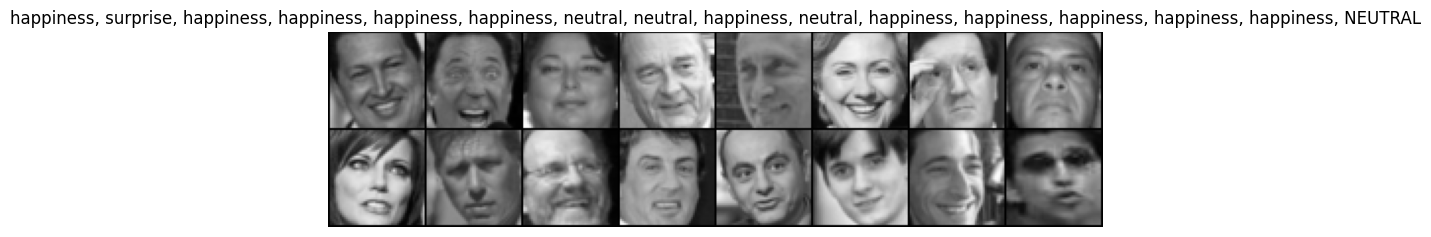

In [5]:
# Mapping depuis le CSV
df_labels = pd.read_csv(CSV_PATH).dropna(subset=["emotion","image"])
emotions = sorted(df_labels["emotion"].astype(str).unique())
label_to_index = {e:i for i,e in enumerate(emotions)}
index_to_label = {i:e for e,i in label_to_index.items()}
print("Classes:", emotions)

# Prétraitements (grayscale, 48x48, normalize)
transform_baseline = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48,48)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Datasets
full_dataset  = FacialExpressionDataset(CSV_PATH, IMAGES_DIR, label_to_index, transform_baseline)
train_dataset = FacialExpressionDataset(CSV_PATH, IMAGES_DIR, label_to_index, transform_baseline)
val_dataset   = FacialExpressionDataset(CSV_PATH, IMAGES_DIR, label_to_index, transform_baseline)

# Split 80/20
n_total = len(full_dataset)
n_train = int(0.8 * n_total)
n_val   = n_total - n_train
gen = torch.Generator().manual_seed(SEED)
idx_train, idx_val = random_split(range(n_total), [n_train, n_val], generator=gen)

from torch.utils.data import Subset
train_data = Subset(train_dataset, idx_train.indices)
val_data   = Subset(val_dataset,   idx_val.indices)

BATCH_SIZE = 64
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_data,   batch_size=BATCH_SIZE, shuffle=False)

print(f"Total: {n_total} | Train: {len(train_data)} | Val: {len(val_data)}")

# Aperçu visuel de quelques échantillons
images, labels = [], []
for i in range(min(16, len(val_data))):
    x, y = val_data[i]
    images.append(x); labels.append(index_to_label[int(y)])
grid = make_grid(torch.stack(images), nrow=8, padding=1, normalize=True)
plt.figure(figsize=(10,3)); plt.imshow(grid.permute(1,2,0)); plt.axis("off")
plt.title(", ".join(labels)); plt.show()


## 5) Modèle CNN simple

In [6]:
# 2 blocs (Conv+ReLU+Pool) → Flatten → FC+ReLU → FC
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 48 -> 24
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)  # 24 -> 12
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*12*12, 128), nn.ReLU(),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = SimpleCNN(num_classes=len(label_to_index)).to(device)
model


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=9216, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=15, bias=True)
  )
)

## 6) Entraînement

In [7]:
LEARNING_RATE = 1e-3
EPOCHS = 12

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

def batch_accuracy(logits, targets):
    return (logits.argmax(1) == targets).float().mean().item()

history = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}

@torch.no_grad()
def evaluate_val():
    model.eval()
    loss_sum = acc_sum = n = 0
    for x, y in val_loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss_sum += criterion(out, y).item()
        acc_sum  += batch_accuracy(out, y)
        n += 1
    return loss_sum/max(1,n), acc_sum/max(1,n)

for epoch in range(1, EPOCHS+1):
    model.train()
    run_loss = run_acc = n = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        run_loss += loss.item()
        run_acc  += batch_accuracy(out, y)
        n += 1
    train_loss = run_loss/max(1,n)
    train_acc  = run_acc/max(1,n)

    val_loss, val_acc = evaluate_val()
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"epoch {epoch:02d} | train_loss {train_loss:.4f} acc {train_acc:.3f} | val_loss {val_loss:.4f} acc {val_acc:.3f}")

epoch 01 | train_loss 0.9378 acc 0.677 | val_loss 0.7290 acc 0.766
epoch 02 | train_loss 0.6323 acc 0.786 | val_loss 0.6814 acc 0.761
epoch 03 | train_loss 0.5446 acc 0.810 | val_loss 0.5342 acc 0.815
epoch 04 | train_loss 0.4740 acc 0.833 | val_loss 0.5205 acc 0.821
epoch 05 | train_loss 0.4231 acc 0.852 | val_loss 0.5249 acc 0.833
epoch 06 | train_loss 0.3710 acc 0.866 | val_loss 0.5101 acc 0.837
epoch 07 | train_loss 0.3332 acc 0.878 | val_loss 0.5420 acc 0.825
epoch 08 | train_loss 0.2731 acc 0.901 | val_loss 0.5627 acc 0.822
epoch 09 | train_loss 0.2223 acc 0.916 | val_loss 0.6233 acc 0.803
epoch 10 | train_loss 0.1753 acc 0.937 | val_loss 0.6684 acc 0.824
epoch 11 | train_loss 0.1279 acc 0.952 | val_loss 0.7198 acc 0.823
epoch 12 | train_loss 0.0932 acc 0.967 | val_loss 0.7768 acc 0.807


# 7) Courbes (train vs val) + point de surapprentissage

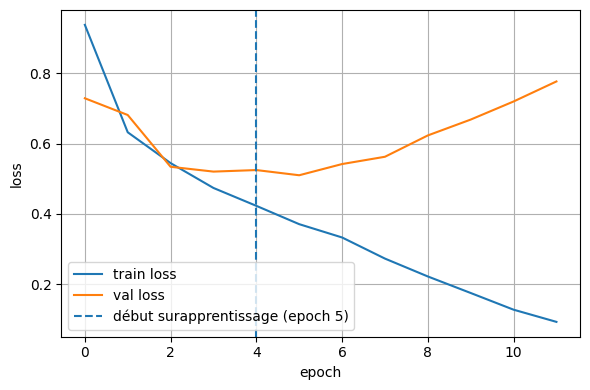

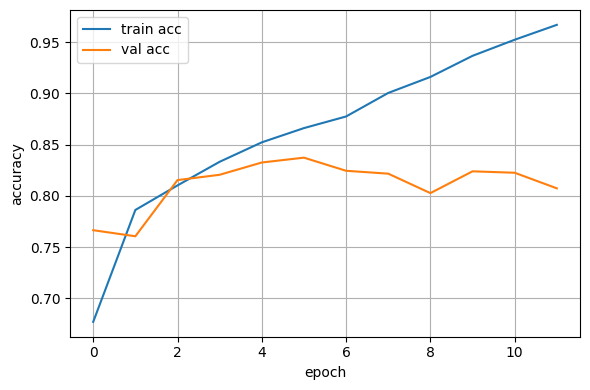

In [8]:
# Courbes de loss (train vs val) + marquage du début de surapprentissage
start_overfit = None
for i in range(1, len(history["val_loss"])):
    if history["val_loss"][i] > history["val_loss"][i-1]:
        start_overfit = i+1
        break

plt.figure(figsize=(6,4))
plt.plot(history["train_loss"], label="train loss")
plt.plot(history["val_loss"], label="val loss")
if start_overfit:
    plt.axvline(start_overfit-1, ls="--", label=f"début surapprentissage (epoch {start_overfit})")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

plt.figure(figsize=(6,4))
plt.plot(history["train_acc"], label="train acc")
plt.plot(history["val_acc"], label="val acc")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

## 8) Optimisation (on corrige l’overfitting)

In [9]:
# Data augmentation côté train
transform_train_aug = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48,48)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
train_dataset_aug = FacialExpressionDataset(CSV_PATH, IMAGES_DIR, label_to_index, transform_train_aug)
train_data_aug = Subset(train_dataset_aug, idx_train.indices)
train_loader_aug = DataLoader(train_data_aug, batch_size=BATCH_SIZE, shuffle=True)

# Modèle avec Dropout
class SimpleCNNWithDropout(nn.Module):
    def __init__(self, num_classes, p=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*12*12, 128), nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model_opt = SimpleCNNWithDropout(num_classes=len(label_to_index), p=0.3).to(device)

LEARNING_RATE_OPT = 8e-4
EPOCHS_OPT = 12
WEIGHT_DECAY = 1e-4

criterion_opt = nn.CrossEntropyLoss()
optimizer_opt = optim.Adam(model_opt.parameters(), lr=LEARNING_RATE_OPT, weight_decay=WEIGHT_DECAY)

history_opt = {"train_loss":[], "val_loss":[], "val_acc":[]}
best_state = None; best_val = float("inf")

for epoch in range(1, EPOCHS_OPT+1):
    model_opt.train()
    run_loss = n = 0
    for x, y in train_loader_aug:
        x, y = x.to(device), y.to(device)
        optimizer_opt.zero_grad()
        out = model_opt(x)
        loss = criterion_opt(out, y)
        loss.backward()
        optimizer_opt.step()
        run_loss += loss.item(); n += 1
    train_loss = run_loss/max(1,n)

    model_opt.eval(); vl=va=vn=0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model_opt(x)
            vl += criterion_opt(out,y).item()
            va += (out.argmax(1)==y).float().mean().item()
            vn += 1
    val_loss = vl/max(1,vn); val_acc = va/max(1,vn)
    history_opt["train_loss"].append(train_loss)
    history_opt["val_loss"].append(val_loss)
    history_opt["val_acc"].append(val_acc)

    if val_loss < best_val:
        best_val = val_loss
        best_state = {k:v.detach().cpu().clone() for k,v in model_opt.state_dict().items()}

    print(f"[opt] epoch {epoch:02d} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} acc {val_acc:.3f}")

if best_state:
    model_opt.load_state_dict(best_state)

[opt] epoch 01 | train_loss 1.0383 | val_loss 0.7153 acc 0.761
[opt] epoch 02 | train_loss 0.7084 | val_loss 0.5958 acc 0.803
[opt] epoch 03 | train_loss 0.6178 | val_loss 0.5578 acc 0.812
[opt] epoch 04 | train_loss 0.5742 | val_loss 0.5331 acc 0.822
[opt] epoch 05 | train_loss 0.5424 | val_loss 0.5027 acc 0.833
[opt] epoch 06 | train_loss 0.4997 | val_loss 0.4859 acc 0.836
[opt] epoch 07 | train_loss 0.4727 | val_loss 0.4927 acc 0.834
[opt] epoch 08 | train_loss 0.4514 | val_loss 0.4930 acc 0.836
[opt] epoch 09 | train_loss 0.4415 | val_loss 0.4566 acc 0.842
[opt] epoch 10 | train_loss 0.4153 | val_loss 0.4724 acc 0.844
[opt] epoch 11 | train_loss 0.3989 | val_loss 0.4572 acc 0.842
[opt] epoch 12 | train_loss 0.3742 | val_loss 0.4548 acc 0.846


## 9) Courbes comparées

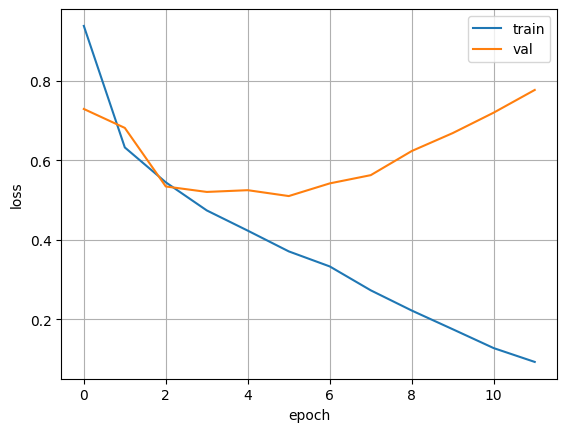

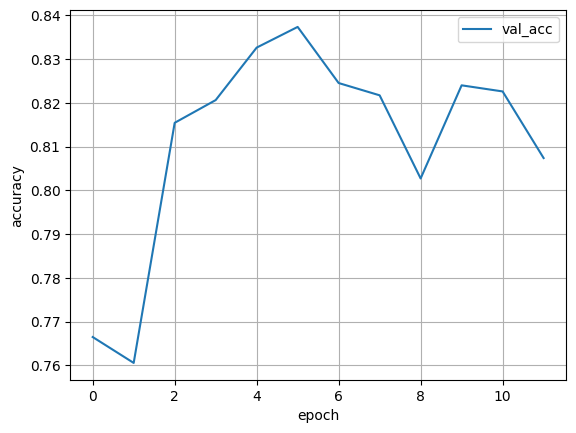

In [12]:
plt.figure()
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(True); plt.show()

plt.figure()
plt.plot(history["val_acc"], label="val_acc")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.grid(True); plt.show()

## 10) Évaluation finale + prédictions visuelles

Baseline  (dernière val_acc): 0.8074
Optimisé  (meilleur checkpoint) val_acc: 0.8456
Optimisé  (recalcule) val_acc: 0.8455


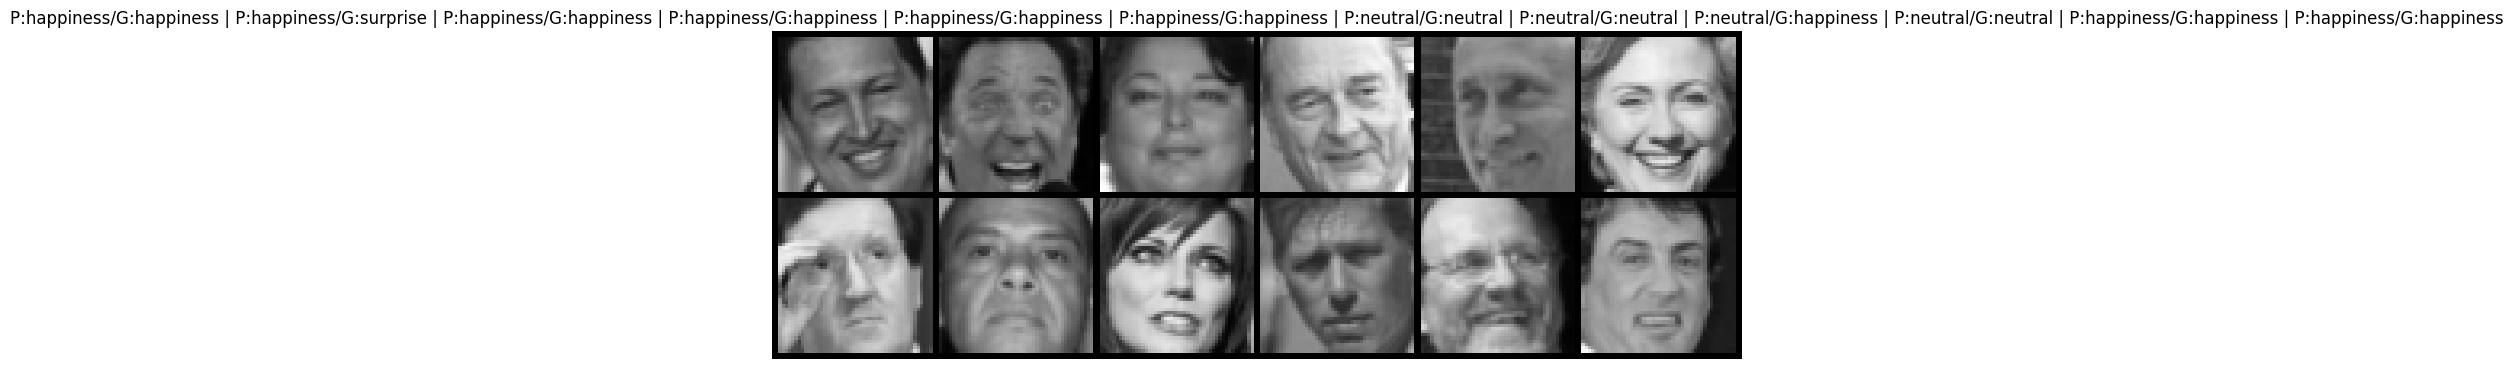

In [13]:
@torch.no_grad()
def loader_accuracy(model, loader):
    model.eval(); correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        pred = model(x).argmax(1)
        correct += (pred==y).sum().item(); total += y.numel()
    return correct/total

print("Baseline  (dernière val_acc):", round(history["val_acc"][-1], 4))
print("Optimisé  (meilleur checkpoint) val_acc:", round(history_opt["val_acc"][-1], 4))
print("Optimisé  (recalcule) val_acc:", round(loader_accuracy(model_opt, val_loader), 4))

# Prévisualisation des prédictions (P: prédiction / G: vérité)
batch = next(iter(val_loader))
x, y = batch[0][:12].to(device), batch[1][:12].to(device)
pred = model_opt(x).argmax(1).cpu().tolist()
true = y.cpu().tolist()

grid = make_grid(x.cpu(), nrow=6, padding=2, normalize=True)
plt.figure(figsize=(10,4))
plt.imshow(grid.permute(1,2,0)); plt.axis("off")
titles = [f"P:{index_to_label[p]}/G:{index_to_label[t]}" for p,t in zip(pred, true)]
plt.title(" | ".join(titles))
plt.tight_layout(); plt.show()